# Etapa 2 — Preparação das imagens (EuroSAT RGB)

Este notebook usa o módulo `notebooks/preprocessamento_py.py` para:

1. Criar os DataLoaders de treino, validação e teste (reutilizando a divisão fixa da Etapa 1, `docs/data_split.json`).
2. Conferir um lote de cada partição (formato, rótulos, média/desvio por canal).
3. Gerar as figuras do relatório em `docs/figuras/`.
4. Provar que validação e teste são determinísticos.

Detalhes e justificativas: `docs/etapa2_preprocessamento.md`.

In [1]:
# Preparação do ambiente: no Colab clona o repositório; localmente garante que
# estamos na RAIZ do projeto (os caminhos ./data e docs/ são relativos a ela).
import os
import sys

EM_COLAB = "google.colab" in sys.modules

if EM_COLAB:
    if not os.path.exists("/content/Projeto-Visao-computacional"):
        !git clone -b preprocessamento https://github.com/GabrielGM3/Projeto-Visao-computacional.git /content/Projeto-Visao-computacional
    %cd /content/Projeto-Visao-computacional
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print("Pasta atual:", os.getcwd())

Pasta atual: c:\PUC Campinas\Oitavo semestre\Visão Computacional\Projeto 1\Projeto-Visao-computacional


## 1. Carregar os DataLoaders

**Atenção:** importar o módulo também importa o `dataset_py.py`, que no topo do arquivo baixa a base EuroSAT para `./data` (na primeira vez demora alguns minutos; depois só verifica que ela existe).

In [2]:
import random
import torch

sys.path.append(os.path.abspath("notebooks"))

from notebooks.preprocessamento_py import (
    IMG_SIZE,
    obter_dataloaders,
    get_transforms_treino,
    get_transforms_avaliacao,
    conferir_lote,
    plotar_grade_lote,
    plotar_aumentos,
)

# No Windows (execução local) os workers são processos novos que reimportam o
# dataset_py.py; usamos 0 para evitar isso. No Colab/Linux usamos 2.
NUM_WORKERS = 0 if os.name == "nt" else 2

treino_dl, val_dl, teste_dl, classes = obter_dataloaders(
    data_dir="./data/eurosat/2750",
    img_size=IMG_SIZE,
    batch_size=64,
    num_workers=NUM_WORKERS,
)

print(f"Classes ({len(classes)}): {classes}")
print(f"Imagens -> treino: {len(treino_dl.dataset)} | validação: {len(val_dl.dataset)} | teste: {len(teste_dl.dataset)}")
print(f"Lotes   -> treino: {len(treino_dl)} | validação: {len(val_dl)} | teste: {len(teste_dl)}")

Carregando divisão fixa existente de: docs/data_split.json

Classes (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Imagens -> treino: 18900 | validação: 4050 | teste: 4050
Lotes   -> treino: 296 | validação: 64 | teste: 64


In [3]:
# Transformações aplicadas em cada partição
print("TREINO:")
print(get_transforms_treino(IMG_SIZE))
print("\nVALIDAÇÃO / TESTE:")
print(get_transforms_avaliacao(IMG_SIZE))

TREINO:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RotacaoMultiplos90(angulos=(0, 90, 180, 270))
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

VALIDAÇÃO / TESTE:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 2. Conferência dos lotes

O que esperar:
- imagens `[64, 3, 224, 224]` em `float32` e rótulos `int64` entre 0 e 9;
- média e desvio por canal **não** ficam exatamente em 0 e 1: usamos as estatísticas do ImageNet, e as imagens da EuroSAT têm outra distribuição de cores (ex.: no treino o canal R fica com média ≈ -0,55). Isso é esperado — o importante é a rede receber os dados na mesma escala do pré-treino.

No **treino** o lote mistura várias classes (shuffle). Em **validação/teste** não há embaralhamento e o `data_split.json` está ordenado por classe, então o primeiro lote contém só `AnnualCrop` — isso é esperado e não afeta as métricas, que são calculadas sobre a partição inteira.

In [4]:
print("===== TREINO =====")
_ = conferir_lote(treino_dl, classes)

===== TREINO =====


Imagens: shape=(64, 3, 224, 224)  dtype=torch.float32
Rótulos: shape=(64,)  dtype=torch.int64
Faixa dos rótulos: min=0  max=9  (válido: 0 a 9)
Faixa dos pixels (normalizados): min=-1.827  max=2.640
  Canal R: média=-0.602  desvio=0.954
  Canal G: média=-0.365  desvio=0.671
  Canal B: média=-0.053  desvio=0.560
Contagem de classes no lote:
  [0] AnnualCrop             9
  [1] Forest                 5
  [2] HerbaceousVegetation   6
  [3] Highway                3
  [4] Industrial             7
  [5] Pasture                8
  [6] PermanentCrop          9
  [7] Residential            4
  [8] River                  7
  [9] SeaLake                6


In [5]:
print("===== VALIDAÇÃO =====")
_ = conferir_lote(val_dl, classes)

===== VALIDAÇÃO =====


Imagens: shape=(64, 3, 224, 224)  dtype=torch.float32
Rótulos: shape=(64,)  dtype=torch.int64
Faixa dos rótulos: min=0  max=0  (válido: 0 a 9)
Faixa dos pixels (normalizados): min=-1.621  max=2.429
  Canal R: média=+0.392  desvio=1.026
  Canal G: média=+0.237  desvio=0.584
  Canal B: média=+0.379  desvio=0.472
Contagem de classes no lote:
  [0] AnnualCrop             64


In [6]:
print("===== TESTE =====")
_ = conferir_lote(teste_dl, classes)

===== TESTE =====


Imagens: shape=(64, 3, 224, 224)  dtype=torch.float32
Rótulos: shape=(64,)  dtype=torch.int64
Faixa dos rótulos: min=0  max=0  (válido: 0 a 9)
Faixa dos pixels (normalizados): min=-1.621  max=2.640
  Canal R: média=+0.179  desvio=1.017
  Canal G: média=+0.100  desvio=0.581
  Canal B: média=+0.265  desvio=0.467
Contagem de classes no lote:
  [0] AnnualCrop             64


## 3. Figuras para o relatório

### 3.1 Lote de treino (com as variações aleatórias)

Figura salva em: docs/figuras/lote_treino.png


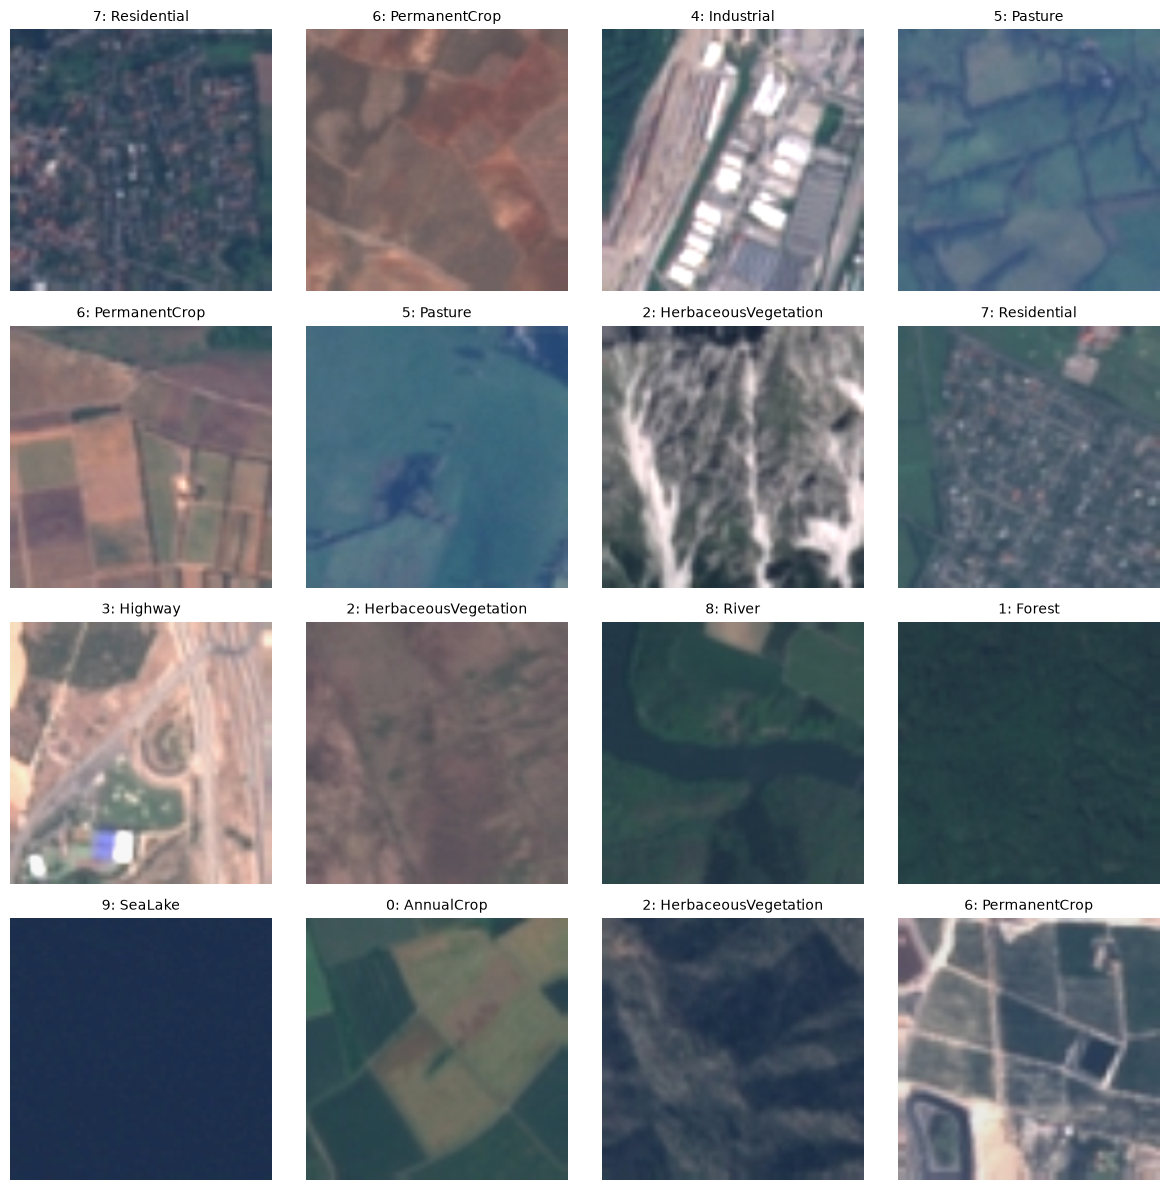

In [7]:
# Sementes fixas só para a figura ser reproduzível (mesmas variações a cada execução)
random.seed(0)
torch.manual_seed(0)

plotar_grade_lote(treino_dl, classes, salvar_em="docs/figuras/lote_treino.png")

### 3.2 Mesma imagem: original x versões aumentadas

Escolhemos uma imagem de `River`, em que giros e espelhamentos são fáceis de perceber.

Figura salva em: docs/figuras/aumentos.png


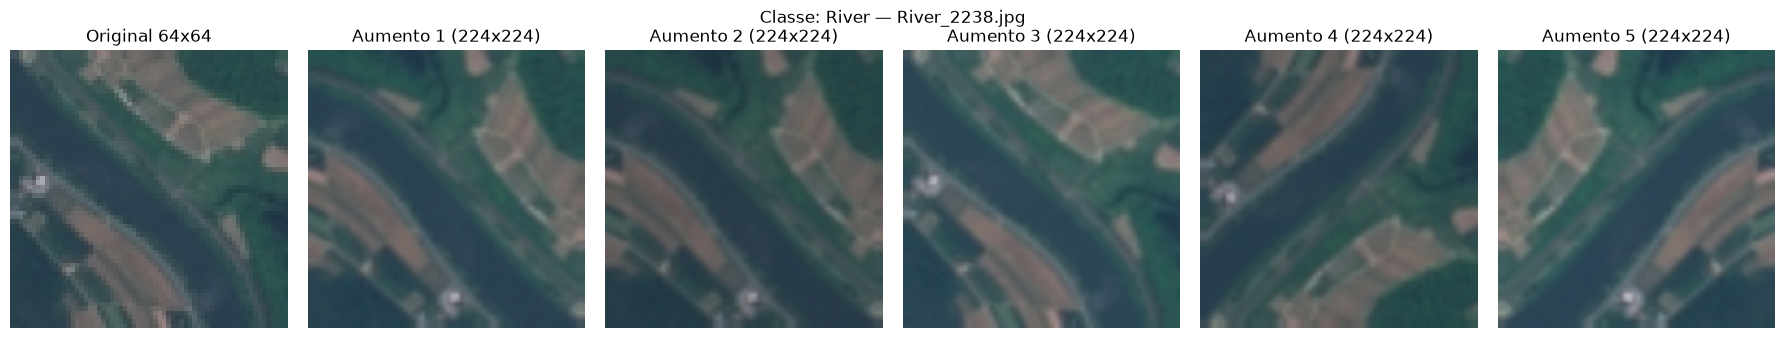

In [8]:
treino_ds = treino_dl.dataset

# Primeira imagem da classe River no treino
idx_rio = next(i for i, (_, y) in enumerate(treino_ds.samples) if classes[y] == "River")

# Sementes fixas só para a figura sair igual a cada execução
random.seed(0)
torch.manual_seed(0)

plotar_aumentos(treino_ds, idx=idx_rio, n=5, salvar_em="docs/figuras/aumentos.png")

### 3.3 Lote de validação (sem variações)

O `val_dl` oficial não é embaralhado e o `data_split.json` está ordenado por classe, então o seu primeiro lote teria só `AnnualCrop`. Para a figura, sorteamos uma **amostra fixa de 64 imagens** da validação (semente 42), o que mostra várias classes. As imagens recebem as mesmas transformações de avaliação (sem variações aleatórias).

Isso serve **apenas para visualização**: as métricas de validação e teste continuam sendo calculadas sobre a partição inteira, com o `val_dl` oficial.


Figura salva em: docs/figuras/lote_validacao.png


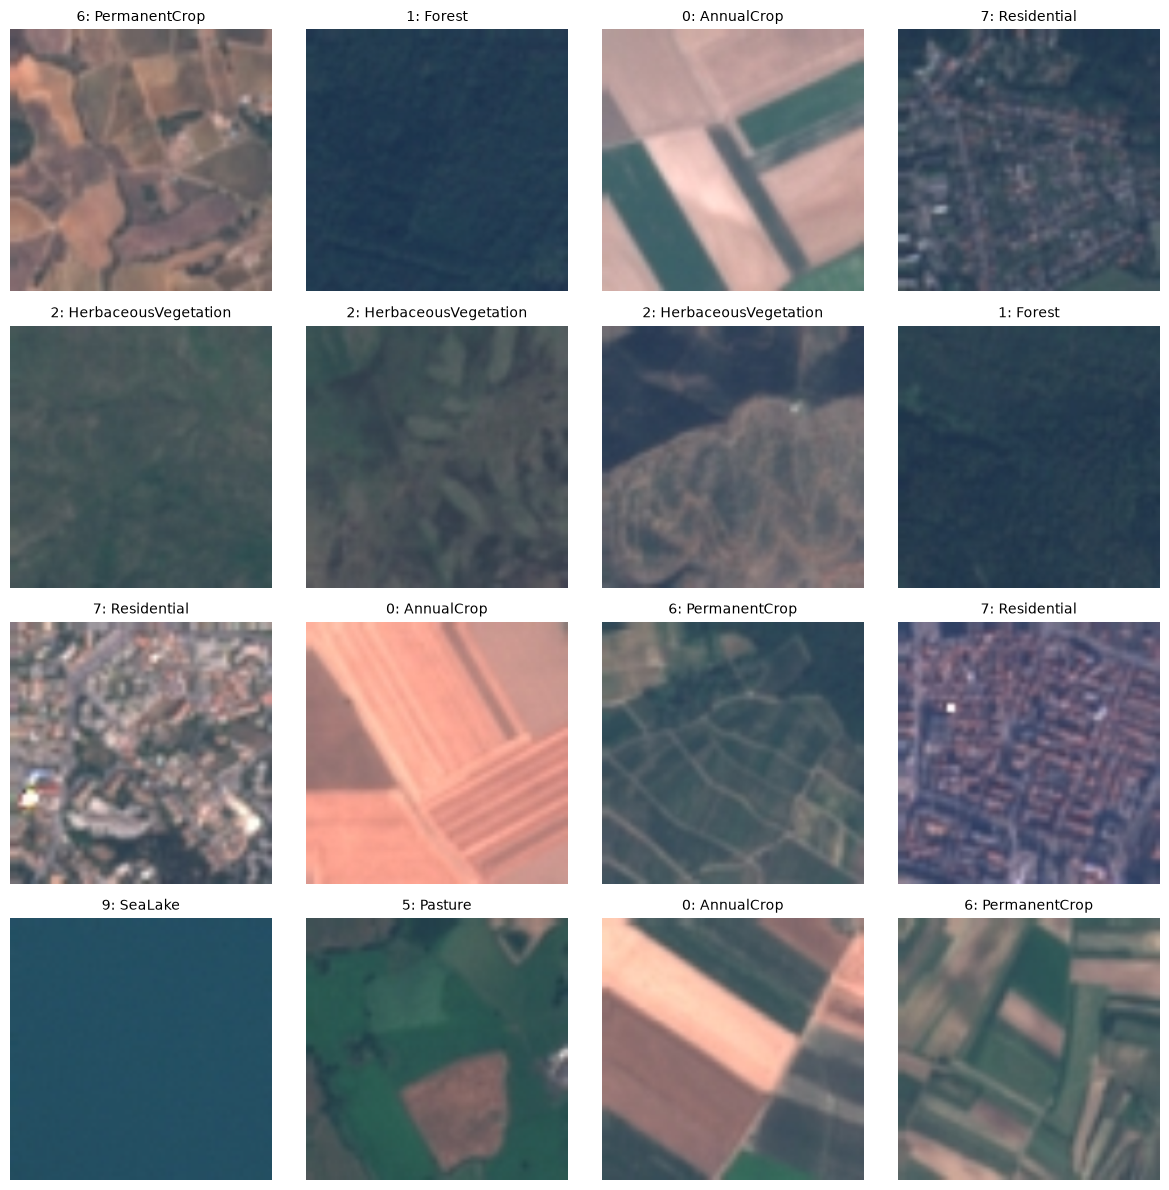

In [9]:
from torch.utils.data import Subset, DataLoader

# Amostra aleatória fixa apenas para visualização; o val_dl oficial continua sem embaralhamento.
val_ds = val_dl.dataset
indices_vis = random.Random(42).sample(range(len(val_ds)), 64)
val_vis_dl = DataLoader(Subset(val_ds, indices_vis), batch_size=64, shuffle=False)

plotar_grade_lote(val_vis_dl, classes, salvar_em="docs/figuras/lote_validacao.png")

## 4. Validação e teste são determinísticos?

Carregamos a mesma imagem duas vezes. Em validação/teste os tensores devem ser **idênticos**; no treino, por causa das variações aleatórias, normalmente são diferentes.

In [10]:
val_ds = val_dl.dataset
teste_ds = teste_dl.dataset

for nome, ds in [("validação", val_ds), ("teste", teste_ds)]:
    for idx in [0, len(ds) // 2, len(ds) - 1]:
        a, _ = ds[idx]
        b, _ = ds[idx]
        print(f"{nome:<10} idx={idx:<5} iguais? {torch.equal(a, b)}")
        assert torch.equal(a, b), "Validação/teste deveriam ser determinísticos!"

# Duas leituras do primeiro lote do DataLoader de validação
lote1, rot1 = next(iter(val_dl))
lote2, rot2 = next(iter(val_dl))
print(f"\nPrimeiro lote da validação igual nas duas leituras? "
      f"{torch.equal(lote1, lote2) and torch.equal(rot1, rot2)}")

# Para comparação: no treino a mesma imagem muda a cada leitura
iguais_treino = sum(torch.equal(treino_ds[0][0], treino_ds[0][0]) for _ in range(10))
print(f"Treino: leituras repetidas idênticas em {iguais_treino} de 10 tentativas (esperado: poucas ou nenhuma)")

validação  idx=0     iguais? True
validação  idx=2025  iguais? True
validação  idx=4049  iguais? True
teste      idx=0     iguais? True
teste      idx=2025  iguais? True
teste      idx=4049  iguais? True



Primeiro lote da validação igual nas duas leituras? True
Treino: leituras repetidas idênticas em 0 de 10 tentativas (esperado: poucas ou nenhuma)


## Resumo

- DataLoaders prontos para as Etapas 3, 4 e 5 via `obter_dataloaders()`.
- Treino: Resize 224 + espelhamentos + giros de 90° + ColorJitter leve + normalização ImageNet.
- Validação/teste: apenas Resize 224 + normalização ImageNet (determinístico, comprovado acima).
- Figuras salvas em `docs/figuras/`: `lote_treino.png`, `aumentos.png`, `lote_validacao.png`.